In [14]:


import torch

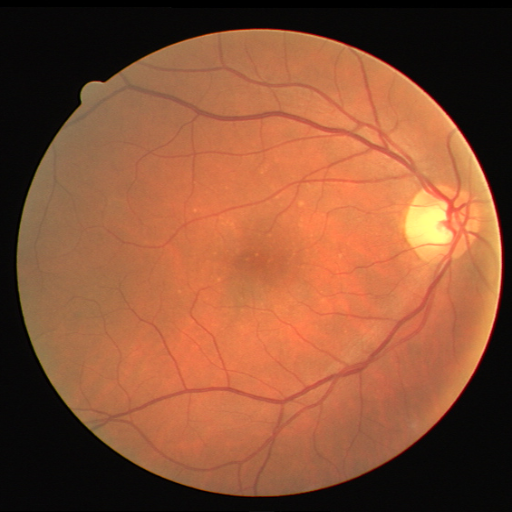

In [13]:
idx = 1
image = Image.open(f"../data/raw/train/image/{idx}.png")
# plt.imshow(image)
# plt.axis("off")
# plt.tight_layout()z
# plt.show()
display(image)

## RetinaDataset

In [19]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

from vessel_seg.data.dataset import RetinaDataset
from vessel_seg.data.transforms import get_image_transform, get_mask_transform, get_augmentation_transform

DATA_DIR = Path("../data/raw")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
train_ds = RetinaDataset(DATA_DIR / "train")
test_ds = RetinaDataset(DATA_DIR / "test")

print(f"train: {len(train_ds)}, test: {len(test_ds)}")
print("images:", train_ds.images.shape, train_ds.images.dtype)
print("masks: ", train_ds.masks.shape, train_ds.masks.unique())
print(f"vessel pixel ratio: {train_ds.masks.mean():.3f}")

train: 80, test: 20
images: torch.Size([80, 3, 512, 512]) torch.float32
masks:  torch.Size([80, 1, 512, 512]) tensor([0., 1.])
vessel pixel ratio: 0.087


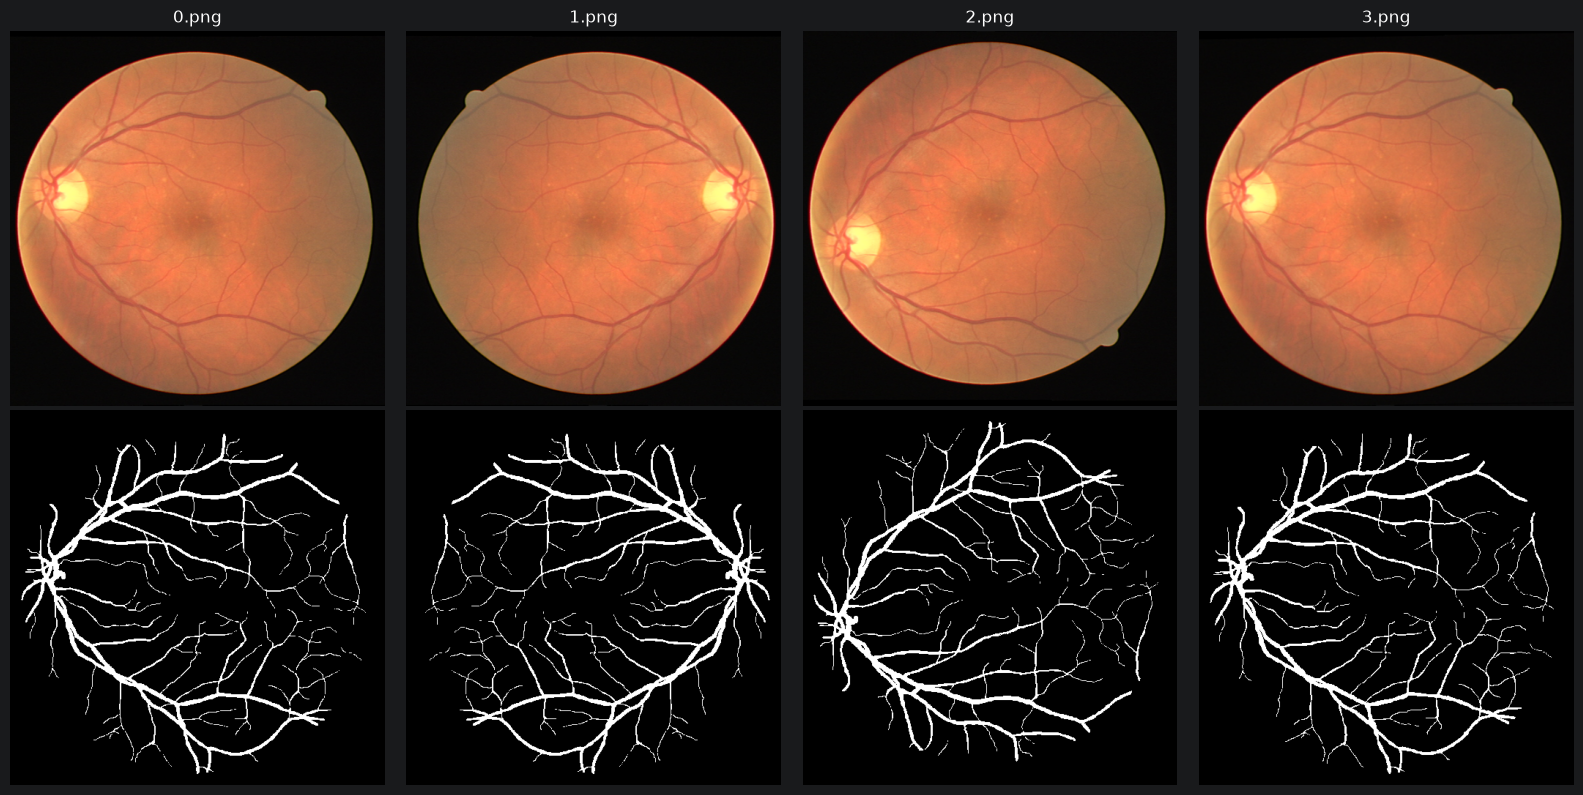

In [6]:
n = 4
fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
for i in range(n):
    image, mask = train_ds[i]
    axes[0, i].imshow(image.permute(1, 2, 0))
    axes[0, i].set_title(train_ds.filenames[i])
    axes[1, i].imshow(mask[0], cmap="gray")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [7]:
loader = DataLoader(train_ds, batch_size=16, shuffle=True)
images, masks = next(iter(loader))
print(images.shape, masks.shape)

torch.Size([16, 3, 512, 512]) torch.Size([16, 1, 512, 512])


Własne transformacje z `transforms.py`:

In [83]:
custom_ds = RetinaDataset(
    DATA_DIR / "train",
    image_transform=get_image_transform(),
    mask_transform=get_mask_transform(),
    augmentation_transform=get_augmentation_transform(),
    indices=[0, 1, 2],
)


torch.Size([3, 512, 512]) torch.Size([1, 512, 512]) tensor([0., 1.])


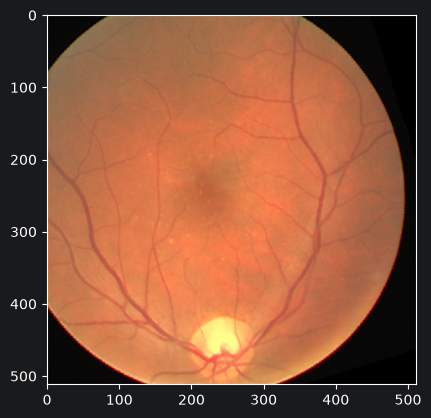

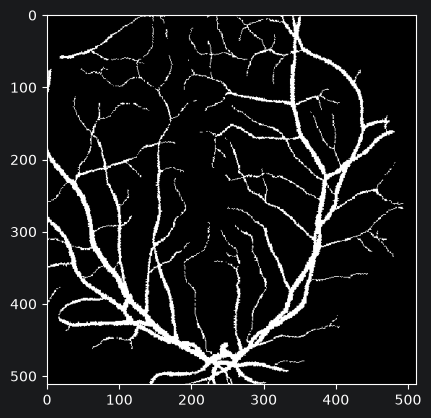

In [90]:
image, mask = custom_ds[0]
print(image.shape, mask.shape, mask.unique())

plt.imshow(image.permute(1,2,0))
plt.show()
plt.imshow(mask[0], cmap="gray")
plt.show()


In [61]:
# get_augmentation_transform()

Compose(
      RandomRotation(degrees=[-180.0, 180.0], interpolation=nearest, expand=False, fill=0)
      RandomApply(    RandomResizedCrop(size=(512, 512), scale=(0.625, 1), ratio=(1, 1), interpolation=bilinear, antialias=True))
)